# Perception-Guided RL for Ballbot Navigation on Uneven Terrain — draft notebook

**Nebiyu Tadesse · AI for Robotics · draft for instructor review**

This notebook accompanies the draft paper (`paper/main.pdf`). It runs end-to-end on the *sample data that ships with the repository*
(small trained policies and result CSVs under `outputs/study/sample/`), so no dataset download is needed. The data in this project
are **self-generated MuJoCo rollouts on procedural Perlin terrains**.

| Section | What it shows | Status |
|---|---|---|
| 1 | Setup | done |
| 2 | Environment, sensing (proprioception + depth), terrain difficulty | done |
| 3 | Physics fix: omniwheel contact-frame alignment | done |
| 4 | Roll out a trained policy, plot trajectory / tilt | done (sample policies) |
| 5 | Tiny PPO training demo (pipeline smoke test) | done |
| 6 | Held-out evaluation (success, fall, return, time-to-goal) | prototype |
| 7 | Hypothesis tests H1 / H2 on the saved result tables | prototype |
| 8 | H3 (waypoint) and remaining work | partly done (see paper); placeholder list below |

**To run:** `pip install -r requirements.txt` (the `noise` package is optional — a NumPy fallback is used when it cannot be built, e.g. on Windows),
then `jupyter lab`. On a headless Linux box set `MUJOCO_GL=egl` before starting Jupyter.

In [1]:
import os, sys, json, time, platform
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "ballbot_gym").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "scripts" / "study")]
if platform.system() == "Linux" and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")

import numpy as np, pandas as pd, yaml, matplotlib.pyplot as plt
import mujoco, torch, stable_baselines3 as sb3, gymnasium as gym
import ballbot_gym  # registers ballbot-v0.1
from ballbot_rl.training.utils import make_ballbot_env

print("repo root      :", ROOT)
print("mujoco / sb3 / torch / gymnasium:", mujoco.mj_versionString(), sb3.__version__, torch.__version__, gym.__version__)
np.random.seed(0); torch.manual_seed(0)
SAMPLE = ROOT / "outputs" / "study" / "sample"
print("sample data    :", sorted(p.name for p in SAMPLE.iterdir()))

repo root      : C:\Users\Owner\Documents\GitHub\openballbot-rl
mujoco / sb3 / torch / gymnasium: 3.13.0 2.9.2 2.11.0+cu128 1.4.0
sample data    : ['depth_frozen_s0', 'h1_results.csv', 'h2_results.csv', 'proprio_s0']


## 2. Environment, sensing and terrain difficulty
Observation = 15-d proprioception (orientation, angular velocity, velocity, wheel speeds, previous action) and, optionally, two $64\times64$ depth images.
Terrain difficulty is the Perlin **amplitude** `A` (we added this parameter; the default amplitude 1.0 gives ~46° mean slope, far above the 20° tilt limit).

In [2]:
def build_env(cfg_path, cameras=True, seed=0, overrides=None):
    cfg = yaml.safe_load(open(cfg_path))
    cfg["camera"]["enabled"] = cameras
    for k, v in (overrides or {}).items():
        sect, key = k.split("."); cfg[sect][key] = v
    env_config = {k: cfg[k] for k in ("camera", "env", "logging")}
    env = make_ballbot_env(terrain_config=cfg["terrain"], reward_config=cfg["reward"],
                           env_config=env_config, seed=seed, eval_env=True)()
    return env, cfg

env, cfg = build_env("configs/env/perlin_directional_train.yaml", cameras=True)
obs, info = env.reset(seed=3)
print({k: v.shape for k, v in obs.items()})
print("action space:", env.action_space, "| goal progress [m]:", cfg["env"]["goal_progress"], "| max steps:", cfg["env"]["max_ep_steps"])
prop = pd.DataFrame({k: np.round(v, 3) for k, v in obs.items() if not k.startswith("rgbd") and k != "relative_image_timestamp"}).T
prop.columns = ["x", "y", "z"]; prop

{'orientation': (3,), 'angular_vel': (3,), 'vel': (3,), 'motor_state': (3,), 'actions': (3,), 'rgbd_0': (1, 64, 64), 'rgbd_1': (1, 64, 64), 'relative_image_timestamp': (1,)}
action space: Box(-1.0, 1.0, (3,), float32) | goal progress [m]: 2.0 | max steps: 800


,x,y,z
orientation,0.0,0.0,0.0
angular_vel,0.0,0.0,0.0
vel,0.0,0.0,0.0
motor_state,0.0,0.0,0.0
actions,0.0,0.0,0.0


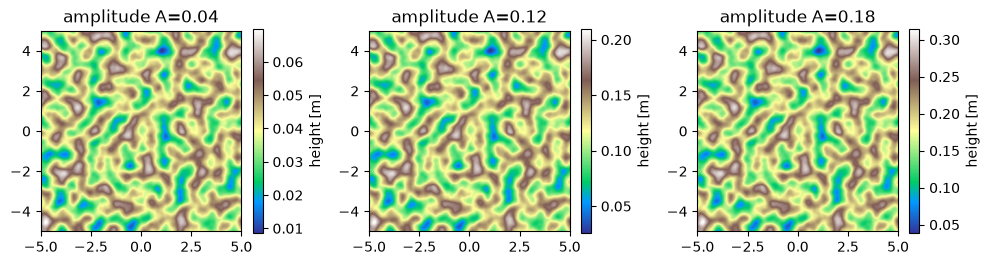

,amplitude,mean_slope_deg,p95_slope_deg,max_slope_deg,height_std_m
0,0.02,1.34,2.34,3.67,0.01
1,0.04,2.67,4.67,7.31,0.01
2,0.08,5.32,9.27,14.40,0.02
3,0.12,7.94,13.76,21.06,0.03
4,0.14,9.23,15.94,24.19,0.04
5,0.16,10.50,18.08,27.17,0.04
6,0.18,11.76,20.17,30.00,0.05
7,0.20,13.00,22.20,32.68,0.05
8,1.00,46.18,63.89,72.68,0.25


In [3]:
# terrain heightmaps at three difficulty levels + slope statistics
from ballbot_gym.terrain.perlin import generate_perlin_terrain
fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
for a, A in zip(ax, (0.04, 0.12, 0.18)):
    t = generate_perlin_terrain(293, 25.0, 4, 0.2, 2.0, A, 100000).reshape(293, 293) * 2.0
    im = a.imshow(t, extent=[-5, 5, -5, 5], cmap="terrain"); a.set_title(f"amplitude A={A}")
    plt.colorbar(im, ax=a, fraction=0.046, label="height [m]")
plt.tight_layout(); plt.show()
pd.read_csv(ROOT / "outputs/study/results/terrain_slopes.csv").round(2)

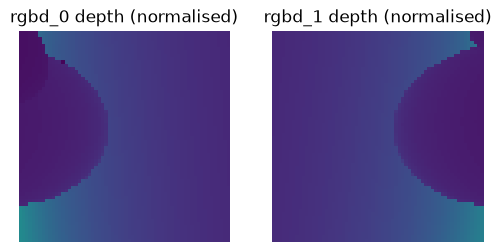

In [4]:
# what the two depth cameras see after a few settling steps (zero action)
for _ in range(20):
    obs, *_ = env.step(np.zeros(3, dtype=np.float32))
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for k, a in zip(("rgbd_0", "rgbd_1"), ax):
    a.imshow(obs[k][0], vmin=0, vmax=1); a.set_title(f"{k} depth (normalised)"); a.axis("off")
plt.show(); env.close()

## 3. Physics fix: omniwheel contact frames
The wheels are capsules with anisotropic friction (`friction="0.001 1.0"`). That only models an omniwheel if the first contact tangent `t1` is the capsule axis.
Stock MuJoCo does not guarantee it (the original repo needs a source patch). `ContactFrameStepper` re-implements the patch in Python.

In [5]:
import importlib.resources
from ballbot_gym.utils.contact_frame import ContactFrameStepper

def alignment(fix, n_steps=150):
    xml = str(importlib.resources.files("ballbot_gym.models") / "ballbot.xml")
    m = mujoco.MjModel.from_xml_path(xml); d = mujoco.MjData(m)
    m.hfield_data = np.zeros(m.hfield_nrow[0] * m.hfield_ncol[0]); mujoco.mj_resetData(m, d)
    d.joint("base_free_joint").qpos[2] += 0.01; d.joint("ball_free_joint").qpos[2] += 0.01
    st = ContactFrameStepper(m, fix_frames=fix); rng = np.random.default_rng(1)
    for _ in range(n_steps):
        d.ctrl[:] = rng.uniform(-3, 3, 3); st.step(d)
    out = {}
    for i in range(d.ncon):
        c = d.contact[i]; names = [mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_GEOM, g) for g in c.geom]
        if "the_ball" in names and any("wheel" in n for n in names):
            w = c.geom[[("wheel" in n) for n in names].index(True)]
            out[names[1]] = round(float(abs(d.geom_xmat[w].reshape(3, 3)[:, 2] @ c.frame[3:6])), 3)
    return out

pd.DataFrame({"stock MuJoCo": alignment(False), "with frame fix": alignment(True)})

,stock MuJoCo,with frame fix
wheel_mesh_0,0.991,1.0
wheel_mesh_1,0.093,1.0
wheel_mesh_2,0.989,1.0


## 4. Roll out a trained policy
`outputs/study/sample/` contains small policies trained with `scripts/study/train_ppo.py` (see the paper for the training budget).

In [6]:
from evaluate import _load_policy, _normalize

def rollout(run_dir, variant, seed, amplitude, condition=None, ckpt="final_model"):
    model, vn = _load_policy(run_dir, variant, ckpt)
    over = {"terrain.config": None}
    env, cfg = build_env("configs/env/perlin_directional_train.yaml", cameras=(variant != "proprio"))
    base = env.unwrapped
    base.terrain_config["config"].update(seed=int(seed), amplitude=float(amplitude)); base.terrain_config["config"].pop("amplitude_range", None)
    for k, v in (condition or {}).items(): setattr(base, k, v)
    obs, info = env.reset(seed=int(seed))
    xs, tilts, rets = [info["pos2d"].copy()], [], 0.0
    while True:
        with torch.no_grad():
            a, _ = model.predict(_normalize(obs, vn), deterministic=True)
        obs, r, term, trunc, info = env.step(a)
        rets += r; xs.append(info["pos2d"].copy())
        tilts.append(float(np.degrees(np.linalg.norm(obs["orientation"]))))
        if term or trunc: break
    env.close()
    return np.array(xs), np.array(tilts), rets, info

runs = sorted(p for p in SAMPLE.iterdir() if p.is_dir())
print("sample policies:", [r.name for r in runs])

sample policies: ['depth_frozen_s0', 'proprio_s0']


loading encoder from C:\Users\Owner\Documents\GitHub\openballbot-rl\outputs\encoders\encoder_epoch_53
This may be due to device differences (CUDA vs CPU). Continuing anyway...
loading encoder from C:\Users\Owner\Documents\GitHub\openballbot-rl\outputs\encoders\encoder_epoch_53
This may be due to device differences (CUDA vs CPU). Continuing anyway...


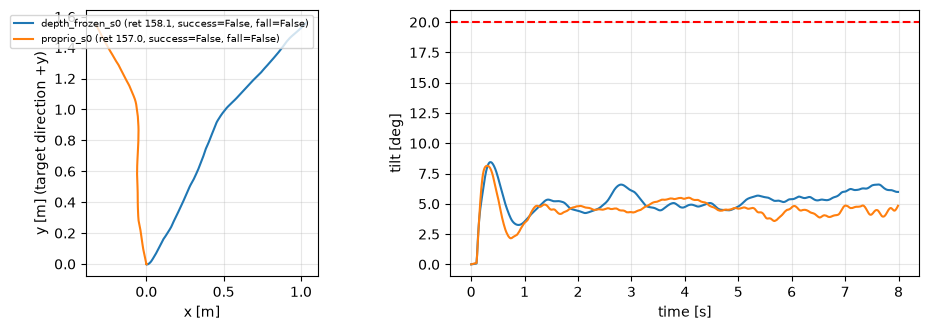

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for run in runs:
    variant = json.load(open(run / "run_config.json"))["args"]["variant"]
    xs, tilts, ret, info = rollout(run, variant, seed=100000, amplitude=0.08)
    ax[0].plot(xs[:, 0], xs[:, 1], label=f"{run.name} (ret {ret:.1f}, success={info['success']}, fall={info['failure']})")
    ax[1].plot(np.arange(len(tilts)) * 0.01, tilts)
ax[0].set_xlabel("x [m]"); ax[0].set_ylabel("y [m] (target direction +y)"); ax[0].legend(fontsize=7); ax[0].set_aspect("equal"); ax[0].grid(alpha=.3)
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("tilt [deg]"); ax[1].axhline(20, color="r", ls="--"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Tiny PPO training demo (pipeline smoke test, ~1 min)
This is *not* the experiment — the paper's runs use ~10⁶ decisions on 5–20 parallel environments (see `scripts/study/train_ppo.py`).

In [8]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from ballbot_rl.policies import Extractor
cfg = yaml.safe_load(open("configs/env/flat_directional.yaml")); cfg["camera"]["enabled"] = False
env_config = {k: cfg[k] for k in ("camera", "env", "logging")}
venv = DummyVecEnv([make_ballbot_env(terrain_config=cfg["terrain"], reward_config=cfg["reward"], env_config=env_config, seed=i, eval_env=True) for i in range(2)])
venv = VecNormalize(venv, norm_obs=True, norm_reward=True, norm_obs_keys=["orientation", "angular_vel", "vel", "motor_state", "actions"])
model = PPO("MultiInputPolicy", venv, n_steps=256, batch_size=128, n_epochs=4, device="cpu", verbose=0,
            policy_kwargs=dict(features_extractor_class=Extractor, net_arch=dict(pi=[64, 64], vf=[64, 64]), log_std_init=-1.0), seed=0)
t0 = time.time(); model.learn(total_timesteps=4096)
print(f"4096 decisions in {time.time()-t0:.1f}s  ->  {4096/(time.time()-t0):.0f} decisions/s on one process")
venv.close()

4096 decisions in 12.2s  ->  334 decisions/s on one process


## 6. Held-out evaluation on the sample policies
Held-out terrains use Perlin seeds ≥ 100000 (training seeds are < 10000). Metrics per episode: success, fall, return, time-to-goal.

In [9]:
from evaluate import run_job, CONDITIONS
def quick_eval(run, amplitudes=(0.04, 0.12), n=4, cond="clean"):
    variant = json.load(open(run / "run_config.json"))["args"]["variant"]
    cfg = yaml.safe_load(open("configs/env/perlin_directional_train.yaml")); cfg["camera"]["enabled"] = variant != "proprio"
    cfg["camera"].update(CONDITIONS[cond]); rows = []
    for A in amplitudes:
        job = dict(run_dir=str(run), variant=variant, ckpt="final_model", condition=cond, env_cfg=cfg, run_name=run.name,
                   episodes=[(100000 + 7 * i, A) for i in range(n)])
        rows += run_job(job)
    return pd.DataFrame(rows)

df = pd.concat([quick_eval(r) for r in runs])
df.groupby(["run", "amplitude"])[["success", "fell", "ret", "time_to_goal", "speed"]].mean().round(3)

loading encoder from C:\Users\Owner\Documents\GitHub\openballbot-rl\outputs\encoders\encoder_epoch_53
This may be due to device differences (CUDA vs CPU). Continuing anyway...
loading encoder from C:\Users\Owner\Documents\GitHub\openballbot-rl\outputs\encoders\encoder_epoch_53
This may be due to device differences (CUDA vs CPU). Continuing anyway...


loading encoder from C:\Users\Owner\Documents\GitHub\openballbot-rl\outputs\encoders\encoder_epoch_53
This may be due to device differences (CUDA vs CPU). Continuing anyway...
loading encoder from C:\Users\Owner\Documents\GitHub\openballbot-rl\outputs\encoders\encoder_epoch_53
This may be due to device differences (CUDA vs CPU). Continuing anyway...


success  fell      ret  time_to_goal  speed
run             amplitude                                             
depth_frozen_s0 0.04           1.0   0.0  159.562        504.75  0.199
                0.12           1.0   0.0  156.960        522.50  0.193
proprio_s0      0.04           1.0   0.0  162.358        510.75  0.206
                0.12           1.0   0.0  146.864        596.00  0.167

## 7. Hypothesis tests on the saved result tables
`outputs/study/sample/` ships the CSVs produced by `scripts/study/evaluate.py` for the full held-out grid. The same code is used for the paper
(`scripts/study/analyze.py`).

In [10]:
from scipy import stats
H1 = pd.read_csv(SAMPLE / "h1_results.csv")
print(H1.groupby(["variant", "amplitude"])[["success", "fell", "ret"]].mean().round(3))

def per_terrain(df, variant, cond="clean", col="success"):
    g = df[(df.variant == variant) & (df.condition == cond)]
    return g.groupby(["amplitude", "seed"])[col].mean()

def paired(a, b, rng=np.random.default_rng(0)):
    j = pd.concat([a, b], axis=1, join="inner").dropna(); d = (j.iloc[:, 0] - j.iloc[:, 1]).values
    boots = d[rng.integers(0, len(d), (5000, len(d)))].mean(1)
    p = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    return dict(n_terrains=len(d), mean_diff=d.mean(), ci95=tuple(np.percentile(boots, [2.5, 97.5]).round(3)), wilcoxon_p=p)

rows = {}
for col in ("success", "fell", "ret"):
    rows[f"H1 {col}: depth_frozen - proprio"] = paired(per_terrain(H1, "depth_frozen", col=col), per_terrain(H1, "proprio", col=col))
pd.DataFrame(rows).T

                        success   fell      ret
variant      amplitude                         
depth_frozen 0.04         1.000  0.000  158.369
             0.08         1.000  0.000  156.450
             0.12         0.867  0.133  142.379
             0.18         0.333  0.500   93.015
proprio      0.04         1.000  0.000  161.818
             0.08         1.000  0.000  157.494
             0.12         0.933  0.067  140.621
             0.18         0.467  0.367  103.046


,n_terrains,mean_diff,ci95,wilcoxon_p
H1 success: depth_frozen - proprio,120,-0.05,"(-0.125, 0.025)",0.200825
H1 fell: depth_frozen - proprio,120,0.05,"(-0.025, 0.125)",0.200825
H1 ret: depth_frozen - proprio,120,-3.191524,"(-12.125, 5.434)",0.397611


In [11]:
H2 = pd.read_csv(SAMPLE / "h2_results.csv")
t = H2[H2.variant == "depth_frozen"].groupby("condition")[["success", "fell", "ret"]].mean().round(3)
t["drop_vs_clean"] = (t.loc["clean", "success"] - t["success"]).round(3)
t

,success,fell,ret,drop_vs_clean
condition,,,,
blank,0.750,0.217,129.569,-0.017
clean,0.733,0.217,129.357,0.000
dropout_0.2,0.750,0.217,129.426,-0.017
noise_0.05,0.733,0.217,129.403,0.000
noise_0.15,0.733,0.217,129.397,0.000
noise_0.30,0.750,0.217,129.409,-0.017
occlusion_0.25,0.733,0.217,129.397,0.000
occlusion_0.50,0.750,0.217,129.429,-0.017


## 8. Placeholders (to be completed before the final submission)
* **H3** — waypoint task implemented (`env.goal_mode`) and trained once (1M decisions, proprio-only); neither policy reaches the 0.3 m goal radius within 8 s, so H3 is **inconclusive**; needs longer training / more seeds (results in the paper, Sec. V-D).
* Full-budget runs with more training seeds and an end-to-end CNN variant (`--variant depth_e2e`).
* Final statistical tables (all seeds), effect sizes and confidence intervals for the paper's Sec. V.